Initializing Ant Colony Routing Mechanics...
Iteration 01/60: Best Fleet Distance Found = 339.71 km
Iteration 10/60: Best Fleet Distance Found = 309.73 km
Iteration 20/60: Best Fleet Distance Found = 309.73 km
Iteration 30/60: Best Fleet Distance Found = 309.73 km
Iteration 40/60: Best Fleet Distance Found = 309.73 km
Iteration 50/60: Best Fleet Distance Found = 309.73 km
Iteration 60/60: Best Fleet Distance Found = 309.73 km

Convergence Achieved. Total Fleet Transit Distance: 309.73 km


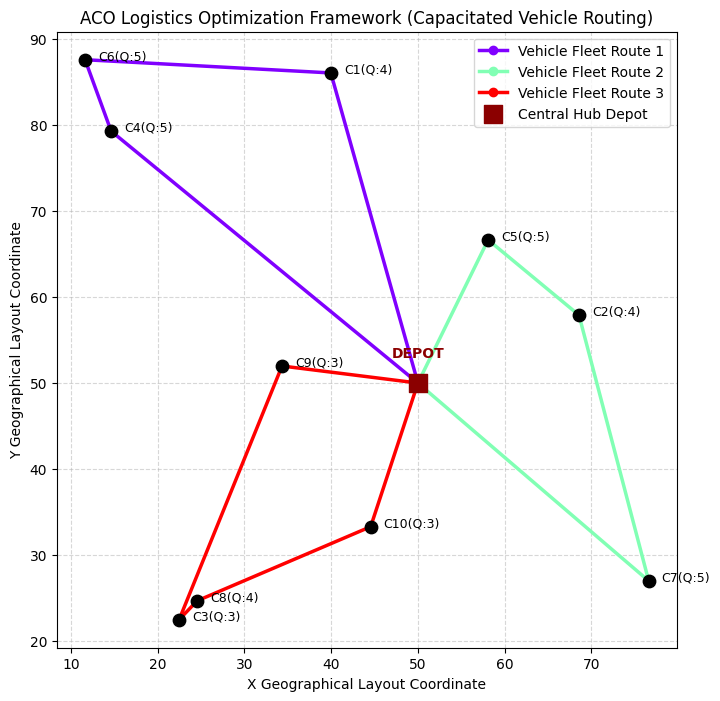

In [3]:
import numpy as np
import matplotlib.pyplot as plt

NUM_CUSTOMERS = 10
VEHICLE_CAPACITY = 15
DEPOT = np.array([50.0, 50.0])

np.random.seed(42)
CUSTOMER_COORDS = np.random.uniform(10, 90, (NUM_CUSTOMERS, 2))
CUSTOMER_DEMANDS = np.random.randint(2, 6, size=NUM_CUSTOMERS)

ALL_COORDS = np.vstack([DEPOT, CUSTOMER_COORDS])
TOTAL_NODES = len(ALL_COORDS)

DIST_MATRIX = np.zeros((TOTAL_NODES, TOTAL_NODES))
for i in range(TOTAL_NODES):
    for j in range(TOTAL_NODES):
        DIST_MATRIX[i, j] = np.linalg.norm(ALL_COORDS[i] - ALL_COORDS[j])

def run_cvrp_aco(num_ants=15, max_iter=50, alpha=1.0, beta=3.0, rho=0.1, q0=100.0):
    pheromones = np.ones((TOTAL_NODES, TOTAL_NODES))
    visibility = 1.0 / (DIST_MATRIX + 1e-10)

    best_distance = float('inf')
    best_routes = []

    for iteration in range(max_iter):
        all_ant_routes = []
        all_ant_distances = []

        for ant in range(num_ants):
            unvisited = set(range(1, TOTAL_NODES))
            routes = []

            while unvisited:
                current_route = [0]
                current_load = 0

                while unvisited:
                    current_node = current_route[-1]
                    candidates = [c for c in unvisited if current_load + CUSTOMER_DEMANDS[c-1] <= VEHICLE_CAPACITY]

                    if not candidates:
                        break

                    probabilities = []
                    for c in candidates:
                        tau = pheromones[current_node, c] ** alpha
                        eta = visibility[current_node, c] ** beta
                        probabilities.append(tau * eta)

                    prob_sum = sum(probabilities)
                    if prob_sum == 0:
                        probabilities = [1.0 / len(candidates)] * len(candidates)
                    else:
                        probabilities = [p / prob_sum for p in probabilities]

                    next_node = np.random.choice(candidates, p=probabilities)
                    current_route.append(next_node)
                    current_load += CUSTOMER_DEMANDS[next_node-1]
                    unvisited.remove(next_node)

                current_route.append(0)
                routes.append(current_route)

            ant_dist = sum(DIST_MATRIX[r[i], r[i+1]] for r in routes for i in range(len(r)-1))
            all_ant_routes.append(routes)
            all_ant_distances.append(ant_dist)

            if ant_dist < best_distance:
                best_distance = ant_dist
                best_routes = routes

        pheromones *= (1.0 - rho)

        for routes in all_ant_routes:
            ant_dist = sum(DIST_MATRIX[r[i], r[i+1]] for r in routes for i in range(len(r)-1))
            for r in routes:
                for i in range(len(r) - 1):
                    pheromones[r[i], r[i+1]] += q0 / ant_dist

        if (iteration + 1) % 10 == 0 or iteration == 0 or iteration == max_iter - 1:
            print(f"Iteration {iteration+1:02d}/{max_iter}: Best Fleet Distance Found = {best_distance:.2f} km")

    return best_routes, best_distance

if __name__ == "__main__":
    print("Initializing Ant Colony Routing Mechanics...")
    optimal_fleet_routes, optimal_fleet_distance = run_cvrp_aco(num_ants=20, max_iter=60)
    print(f"\nConvergence Achieved. Total Fleet Transit Distance: {optimal_fleet_distance:.2f} km")

    fig, ax = plt.subplots(figsize=(8, 8))

    colors = plt.cm.rainbow(np.linspace(0, 1, len(optimal_fleet_routes)))
    for idx, route in enumerate(optimal_fleet_routes):
        route_coords = ALL_COORDS[route]
        ax.plot(route_coords[:, 0], route_coords[:, 1],
                marker='o', linewidth=2.5, color=colors[idx], label=f'Vehicle Fleet Route {idx+1}')

    ax.scatter(CUSTOMER_COORDS[:, 0], CUSTOMER_COORDS[:, 1], color='black', zorder=5, s=80)
    for idx, demand in enumerate(CUSTOMER_DEMANDS):
        ax.text(CUSTOMER_COORDS[idx, 0]+1.5, CUSTOMER_COORDS[idx, 1], f"C{idx+1}(Q:{demand})", fontsize=9)

    ax.scatter(DEPOT[0], DEPOT[1], color='darkred', marker='s', zorder=6, s=180, label='Central Hub Depot')
    ax.text(DEPOT[0]-3, DEPOT[1]+3, "DEPOT", color='darkred', fontweight='bold')

    ax.set_title("ACO Logistics Optimization Framework (Capacitated Vehicle Routing)", fontsize=12)
    ax.set_xlabel("X Geographical Layout Coordinate")
    ax.set_ylabel("Y Geographical Layout Coordinate")
    ax.legend(loc='upper right')
    ax.grid(True, linestyle='--', alpha=0.5)

    plt.show()